In [1]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# GitHub Raw URL
url = "https://raw.githubusercontent.com/tanvipharade/Diabetes-Prediction-Logistic-Regression/refs/heads/main/diabetes_prediction_dataset.csv"

# Load dataset
df = pd.read_csv(url)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [3]:

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nDataset Shape:", df.shape)


Number of Rows: 100000
Number of Columns: 9

Dataset Shape: (100000, 9)


In [4]:

print("First 5 Records:")
display(df.head())

print("Last 5 Records:")
display(df.tail())


First 5 Records:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Last 5 Records:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0
99999,Female,57.0,0,0,current,22.43,6.6,90,0


In [5]:

print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB

Column Names:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Data Types:
gender                  object
age                    float64
hypertension             int64

In [6]:

print("Statistical Summary:")
display(df.describe())

print("\nCategorical Feature Summary:")
display(df.describe(include='object'))


Statistical Summary:


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000



Categorical Feature Summary:


,gender,smoking_history
count,100000,100000
unique,3,6
top,Female,No Info
freq,58552,35816


In [7]:

print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())


Missing Values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Total Missing Values:
0

Duplicate Records:
3854


Diabetes Distribution:
diabetes
0    91500
1     8500
Name: count, dtype: int64

Percentage Distribution:
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


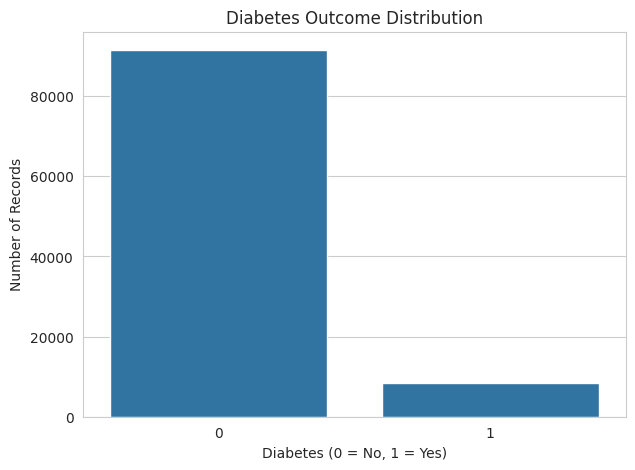

In [8]:

print("Diabetes Distribution:")
print(df['diabetes'].value_counts())

print("\nPercentage Distribution:")
print(df['diabetes'].value_counts(normalize=True) * 100)

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='diabetes')

plt.title('Diabetes Outcome Distribution')
plt.xlabel('Diabetes (0 = No, 1 = Yes)')
plt.ylabel('Number of Records')

plt.show()


In [9]:

# Identify numerical and categorical columns

numerical_cols = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_cols = df.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

print("\nNumber of Numerical Features:", len(numerical_cols))
print("Number of Categorical Features:", len(categorical_cols))


Numerical Columns:
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Categorical Columns:
['gender', 'smoking_history']

Number of Numerical Features: 7
Number of Categorical Features: 2


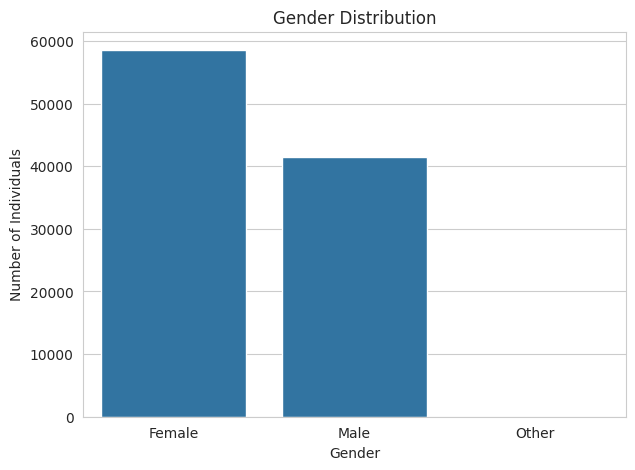

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [10]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='gender')

plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Individuals')

plt.show()

print(df['gender'].value_counts())


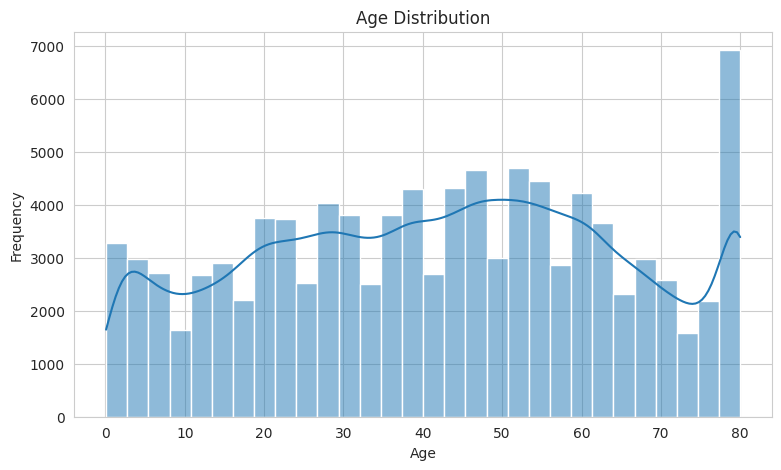

Mean Age: 41.885856
Median Age: 43.0
Minimum Age: 0.08
Maximum Age: 80.0


In [11]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='age',
    bins=30,
    kde=True
)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

print("Mean Age:", df['age'].mean())
print("Median Age:", df['age'].median())
print("Minimum Age:", df['age'].min())
print("Maximum Age:", df['age'].max())


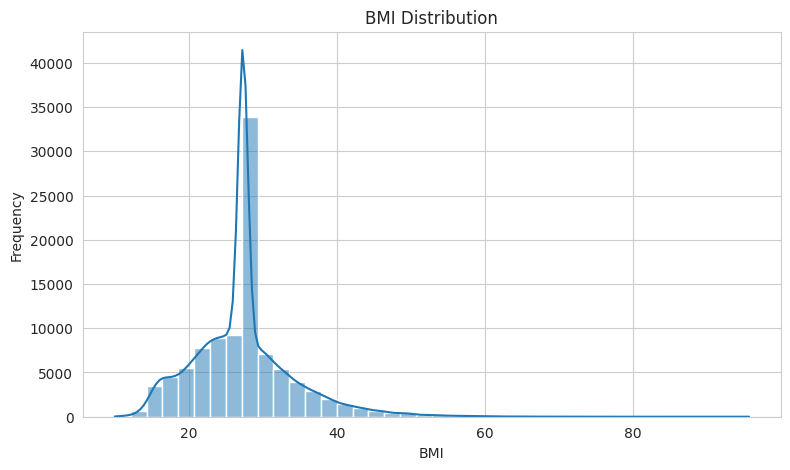

BMI Mean: 27.3207671
BMI Median: 27.32
BMI Minimum: 10.01
BMI Maximum: 95.69


In [12]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='bmi',
    bins=40,
    kde=True
)

plt.title('BMI Distribution')
plt.xlabel('BMI')
plt.ylabel('Frequency')

plt.show()

print("BMI Mean:", df['bmi'].mean())
print("BMI Median:", df['bmi'].median())
print("BMI Minimum:", df['bmi'].min())
print("BMI Maximum:", df['bmi'].max())


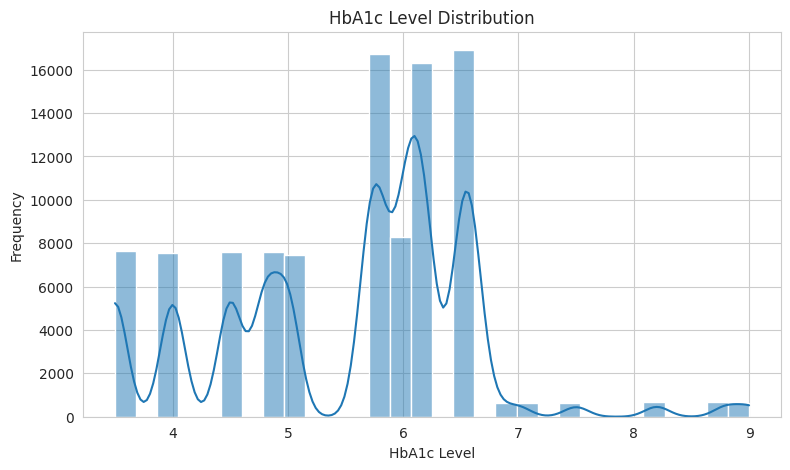

count    100000.000000
mean          5.527507
std           1.070672
min           3.500000
25%           4.800000
50%           5.800000
75%           6.200000
max           9.000000
Name: HbA1c_level, dtype: float64


In [13]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='HbA1c_level',
    bins=30,
    kde=True
)

plt.title('HbA1c Level Distribution')
plt.xlabel('HbA1c Level')
plt.ylabel('Frequency')

plt.show()

print(df['HbA1c_level'].describe())


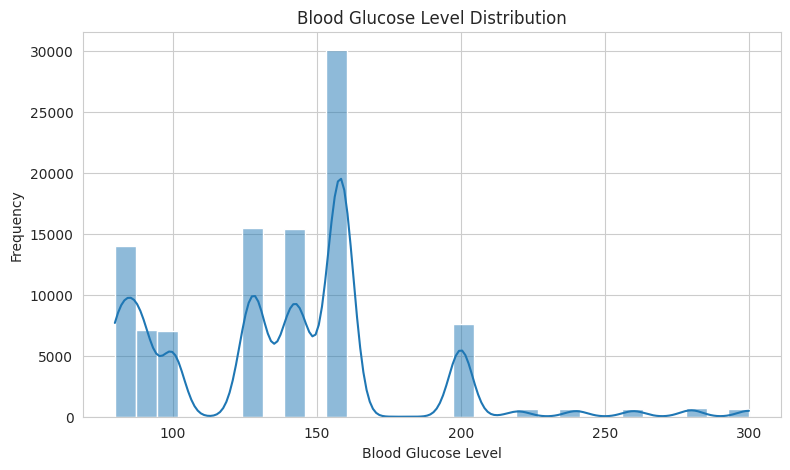

count    100000.000000
mean        138.058060
std          40.708136
min          80.000000
25%         100.000000
50%         140.000000
75%         159.000000
max         300.000000
Name: blood_glucose_level, dtype: float64


In [14]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='blood_glucose_level',
    bins=30,
    kde=True
)

plt.title('Blood Glucose Level Distribution')
plt.xlabel('Blood Glucose Level')
plt.ylabel('Frequency')

plt.show()

print(df['blood_glucose_level'].describe())


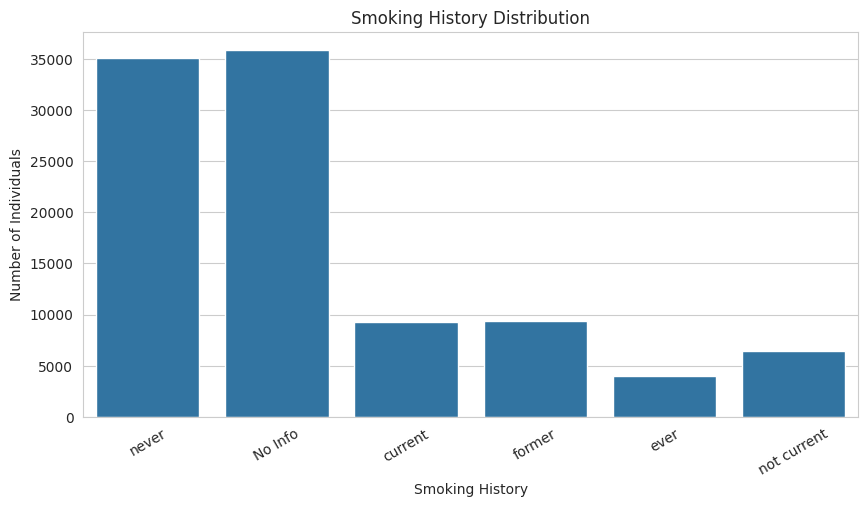

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [15]:

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='smoking_history'
)

plt.title('Smoking History Distribution')
plt.xlabel('Smoking History')
plt.ylabel('Number of Individuals')
plt.xticks(rotation=30)

plt.show()

print(df['smoking_history'].value_counts())


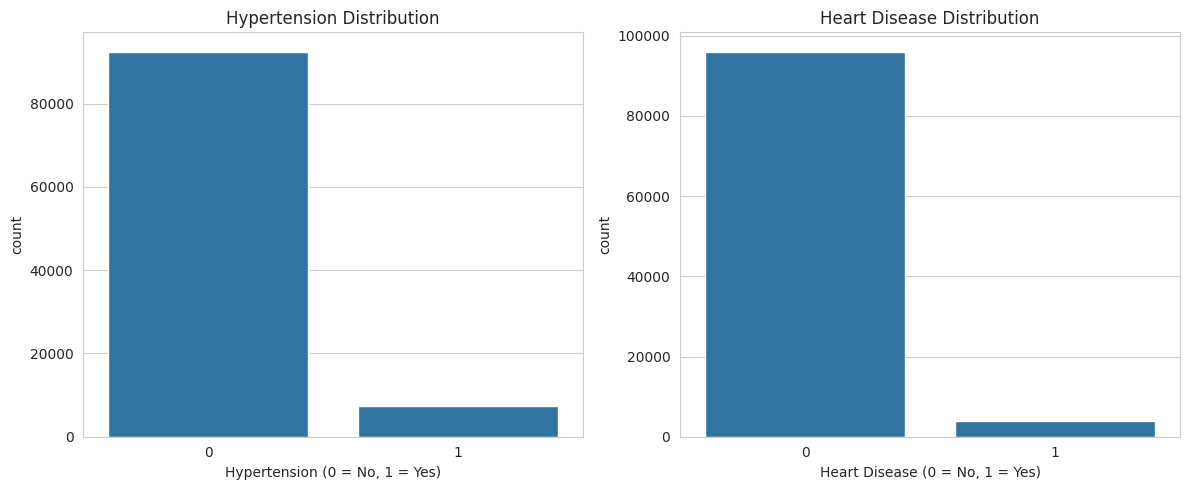

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    data=df,
    x='hypertension',
    ax=axes[0]
)

axes[0].set_title('Hypertension Distribution')
axes[0].set_xlabel('Hypertension (0 = No, 1 = Yes)')

sns.countplot(
    data=df,
    x='heart_disease',
    ax=axes[1]
)

axes[1].set_title('Heart Disease Distribution')
axes[1].set_xlabel('Heart Disease (0 = No, 1 = Yes)')

plt.tight_layout()
plt.show()


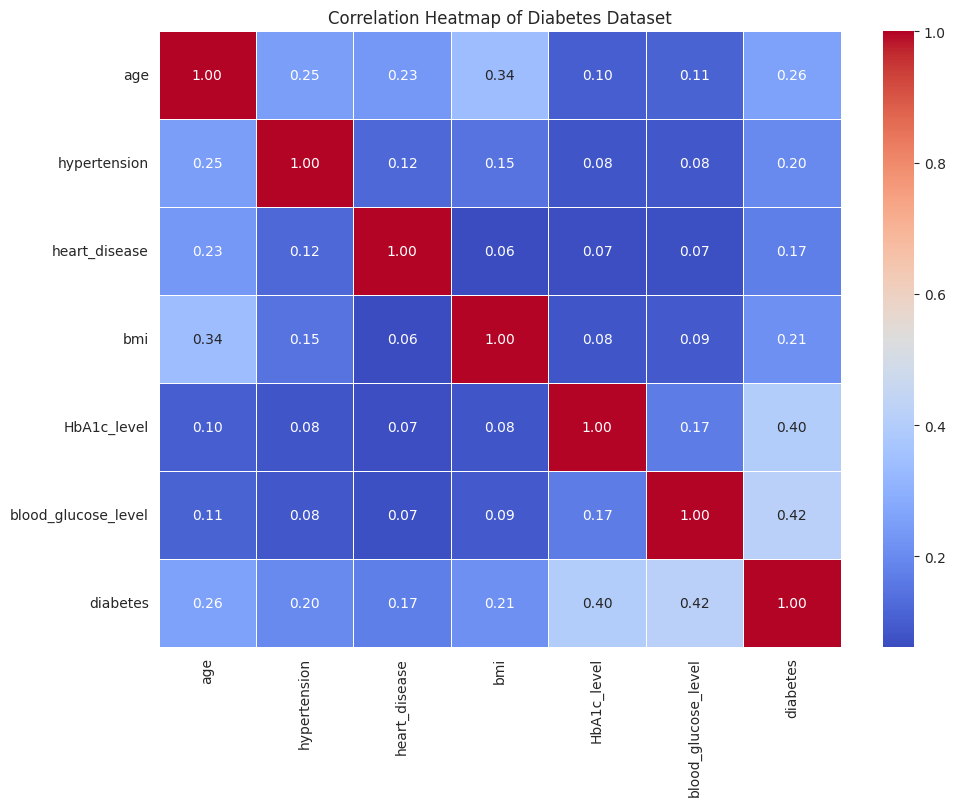

In [17]:

plt.figure(figsize=(11, 8))

correlation = df[numerical_cols].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Diabetes Dataset')
plt.show()


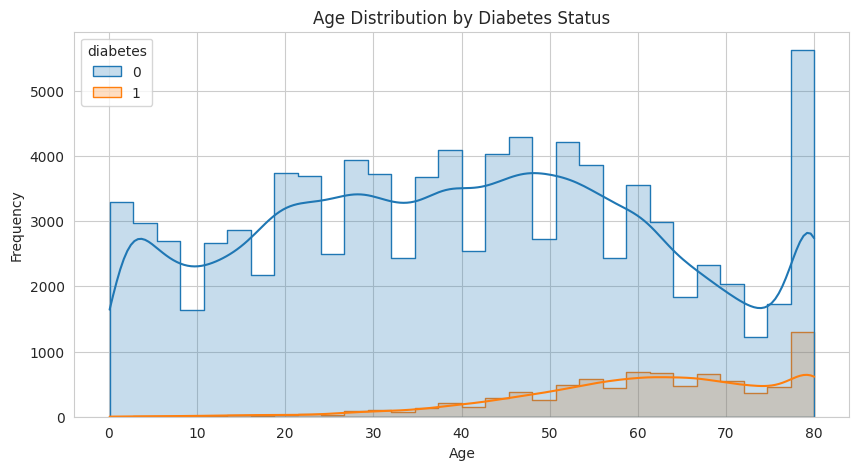

In [18]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='age',
    hue='diabetes',
    bins=30,
    kde=True,
    element='step'
)

plt.title('Age Distribution by Diabetes Status')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()


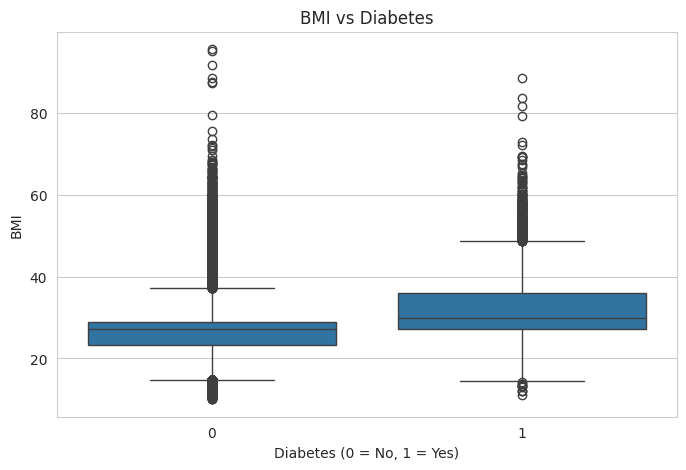

In [19]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='diabetes',
    y='bmi'
)

plt.title('BMI vs Diabetes')
plt.xlabel('Diabetes (0 = No, 1 = Yes)')
plt.ylabel('BMI')

plt.show()


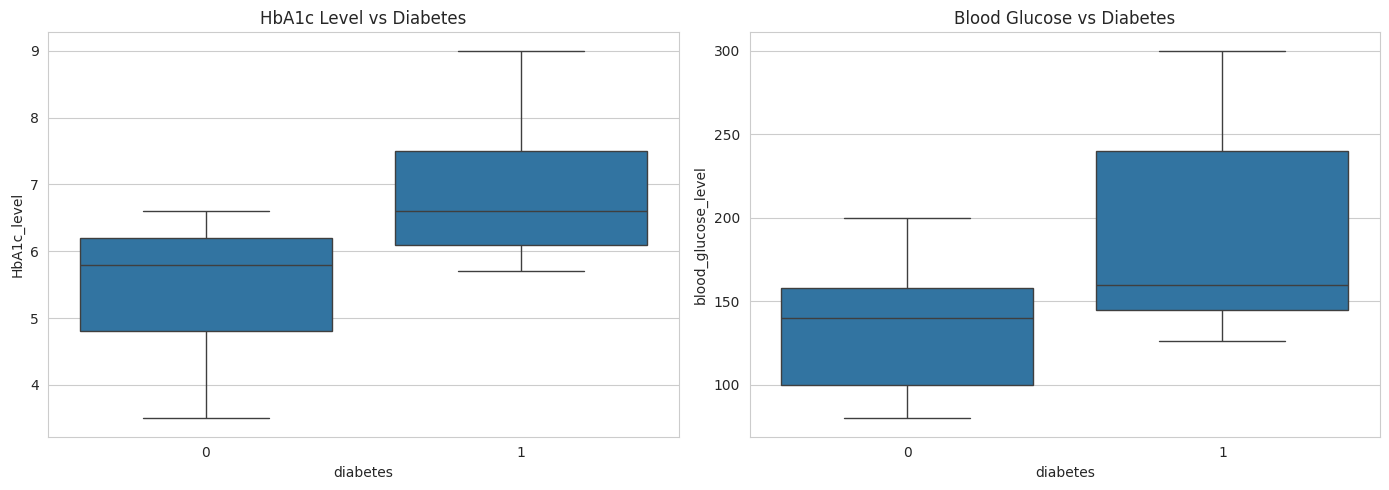

In [20]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x='diabetes',
    y='HbA1c_level',
    ax=axes[0]
)

axes[0].set_title('HbA1c Level vs Diabetes')

sns.boxplot(
    data=df,
    x='diabetes',
    y='blood_glucose_level',
    ax=axes[1]
)

axes[1].set_title('Blood Glucose vs Diabetes')

plt.tight_layout()
plt.show()


Diabetes Percentage by Gender:


diabetes,0,1
gender,,
Female,92.381131,7.618869
Male,90.251026,9.748974
Other,100.000000,0.000000


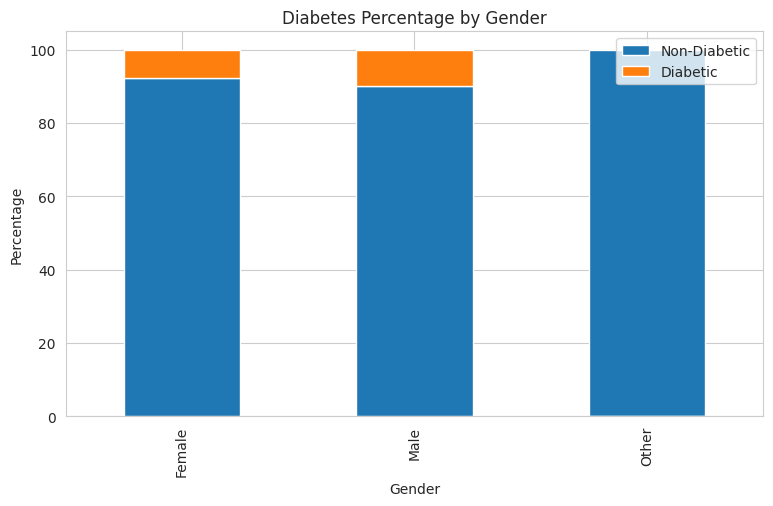

In [21]:

gender_diabetes = pd.crosstab(
    df['gender'],
    df['diabetes'],
    normalize='index'
) * 100

print("Diabetes Percentage by Gender:")
display(gender_diabetes)

gender_diabetes.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Diabetes Percentage by Gender')
plt.xlabel('Gender')
plt.ylabel('Percentage')
plt.legend(['Non-Diabetic', 'Diabetic'])

plt.show()


Diabetes Percentage by Smoking History:


diabetes,0,1
smoking_history,,
No Info,95.940362,4.059638
current,89.791083,10.208917
ever,88.211788,11.788212
former,82.998289,17.001711
never,90.465878,9.534122
not current,89.297348,10.702652


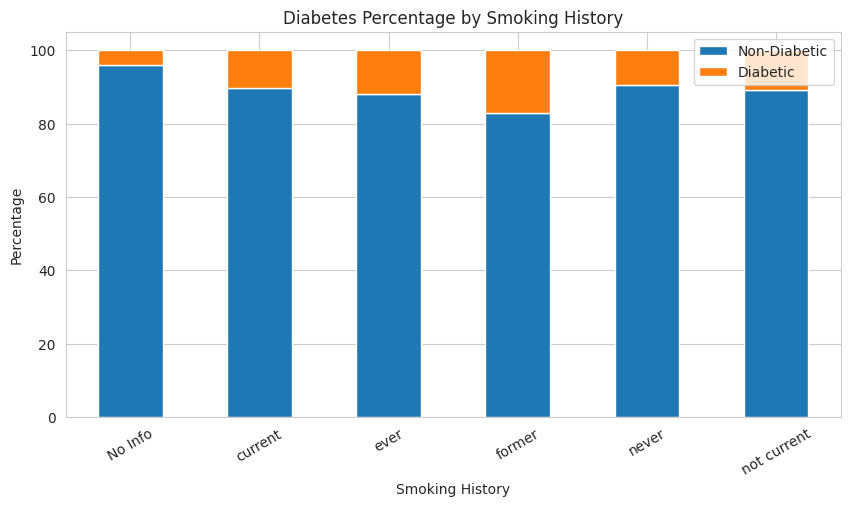

In [22]:

smoking_diabetes = pd.crosstab(
    df['smoking_history'],
    df['diabetes'],
    normalize='index'
) * 100

print("Diabetes Percentage by Smoking History:")
display(smoking_diabetes)

smoking_diabetes.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5)
)

plt.title('Diabetes Percentage by Smoking History')
plt.xlabel('Smoking History')
plt.ylabel('Percentage')
plt.xticks(rotation=30)
plt.legend(['Non-Diabetic', 'Diabetic'])

plt.show()


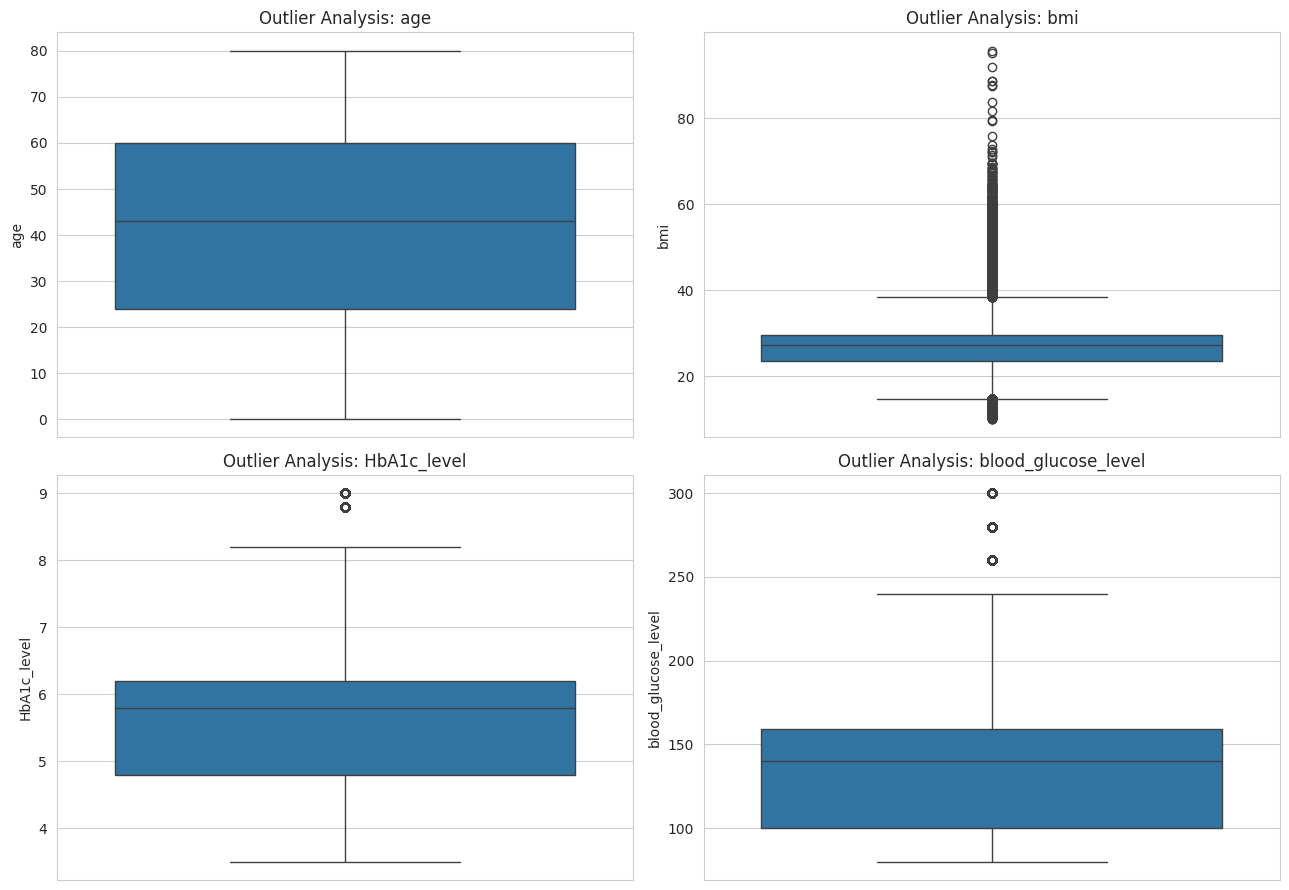

In [23]:

features = [
    'age',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level'
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for feature, ax in zip(features, axes.flatten()):
    sns.boxplot(
        data=df,
        y=feature,
        ax=ax
    )
    ax.set_title(f'Outlier Analysis: {feature}')

plt.tight_layout()
plt.show()


In [24]:

outlier_results = []

for feature in features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_limit) |
        (df[feature] > upper_limit)
    ]

    outlier_results.append({
        'Feature': feature,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit,
        'Outlier Count': len(outliers)
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)


,Feature,Lower Limit,Upper Limit,Outlier Count
0,age,-30.000,114.000,0
1,bmi,14.705,38.505,7086
2,HbA1c_level,2.700,8.300,1315
3,blood_glucose_level,11.500,247.500,2038


In [25]:

# Create a working copy of original dataset

data = df.copy()

print("Original Dataset Shape:", data.shape)

# Check duplicate records
print("Duplicate Records:", data.duplicated().sum())


Original Dataset Shape: (100000, 9)
Duplicate Records: 3854


In [26]:

# Remove exact duplicate records

data = data.drop_duplicates().copy()

print("Dataset after removing duplicates:")
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])

print("\nRemaining Duplicates:", data.duplicated().sum())


Dataset after removing duplicates:
Rows: 96146
Columns: 9

Remaining Duplicates: 0


In [27]:

print("Data Types:")
print(data.dtypes)

print("\nUnique Gender Values:")
print(data['gender'].unique())

print("\nUnique Smoking History Values:")
print(data['smoking_history'].unique())

print("\nTarget Values:")
print(data['diabetes'].unique())


Data Types:
gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

Unique Gender Values:
['Female' 'Male' 'Other']

Unique Smoking History Values:
['never' 'No Info' 'current' 'former' 'ever' 'not current']

Target Values:
[0 1]


In [28]:

# Independent variables
X = data.drop('diabetes', axis=1)

# Dependent variable
y = data['diabetes']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)


Features Shape: (96146, 8)
Target Shape: (96146,)

Input Features:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level']

Target Variable:
diabetes


In [29]:

# Numerical continuous features
numerical_features = [
    'age',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level'
]

# Categorical features
categorical_features = [
    'gender',
    'smoking_history'
]

# Binary numerical features
binary_features = [
    'hypertension',
    'heart_disease'
]

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)
print("Binary Features:", binary_features)


Numerical Features: ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
Categorical Features: ['gender', 'smoking_history']
Binary Features: ['hypertension', 'heart_disease']


In [30]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (76916, 8)
Testing Features: (19230, 8)

Training Target: (76916,)
Testing Target: (19230,)


In [31]:

print("Training Class Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training Class Distribution:
diabetes
0    91.177388
1     8.822612
Name: proportion, dtype: float64

Testing Class Distribution:
diabetes
0    91.180447
1     8.819553
Name: proportion, dtype: float64


In [32]:

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features),
        ('binary', 'passthrough', binary_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

print("Logistic Regression imported successfully!")

Logistic Regression imported successfully!


In [34]:
baseline_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("Logistic Regression pipeline created successfully!")

Logistic Regression pipeline created successfully!


In [35]:
baseline_model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [37]:
y_pred = baseline_model.predict(X_test)

print("Predictions generated successfully!")
print("First 10 Actual Values:", y_test.iloc[:10].values)
print("First 10 Predicted Values:", y_pred[:10])

Predictions generated successfully!
First 10 Actual Values: [0 0 0 0 0 0 0 0 0 0]
First 10 Predicted Values: [0 0 0 0 0 0 0 0 0 0]


In [38]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("MODEL PERFORMANCE")
print("-------------------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

MODEL PERFORMANCE
-------------------------
Accuracy : 95.97 %
Precision: 86.99 %
Recall   : 63.86 %
F1 Score : 73.65 %


In [39]:
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Diabetic", "Diabetic"],
    zero_division=0
))

Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.97      0.99      0.98     17534
    Diabetic       0.87      0.64      0.74      1696

    accuracy                           0.96     19230
   macro avg       0.92      0.81      0.86     19230
weighted avg       0.96      0.96      0.96     19230



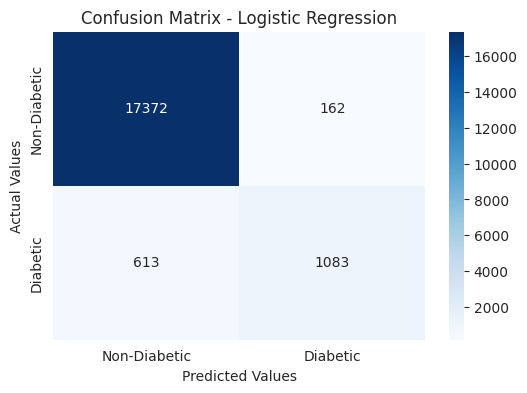

Confusion Matrix:
[[17372   162]
 [  613  1083]]


In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)

plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

print("Confusion Matrix:")
print(cm)

In [41]:
balanced_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ))
])

balanced_model.fit(X_train, y_train)

print("Balanced Logistic Regression model trained successfully!")

Balanced Logistic Regression model trained successfully!


In [42]:
y_pred_balanced = balanced_model.predict(X_test)

print("Balanced model predictions generated!")

Balanced model predictions generated!


In [43]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

balanced_accuracy = accuracy_score(y_test, y_pred_balanced)
balanced_precision = precision_score(y_test, y_pred_balanced)
balanced_recall = recall_score(y_test, y_pred_balanced)
balanced_f1 = f1_score(y_test, y_pred_balanced)

print("BALANCED MODEL PERFORMANCE")
print("----------------------------")
print("Accuracy :", round(balanced_accuracy * 100, 2), "%")
print("Precision:", round(balanced_precision * 100, 2), "%")
print("Recall   :", round(balanced_recall * 100, 2), "%")
print("F1 Score :", round(balanced_f1 * 100, 2), "%")

BALANCED MODEL PERFORMANCE
----------------------------
Accuracy : 88.44 %
Precision: 42.5 %
Recall   : 87.97 %
F1 Score : 57.31 %


In [44]:
import pandas as pd

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Original Model': [
        accuracy, precision, recall, f1
    ],
    'Balanced Model': [
        balanced_accuracy,
        balanced_precision,
        balanced_recall,
        balanced_f1
    ]
})

print(comparison.round(4))

      Metric  Original Model  Balanced Model
0   Accuracy          0.9597          0.8844
1  Precision          0.8699          0.4250
2     Recall          0.6386          0.8797
3   F1 Score          0.7365          0.5731


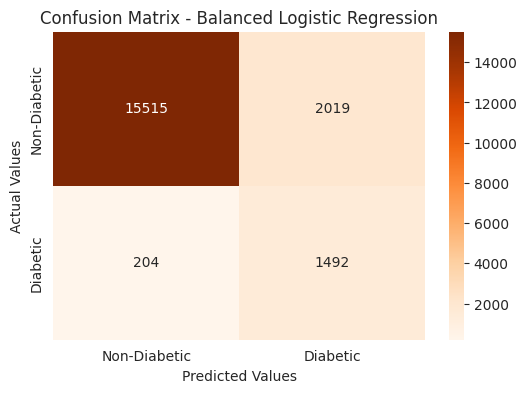

Balanced Confusion Matrix:
[[15515  2019]
 [  204  1492]]


In [45]:
cm_balanced = confusion_matrix(y_test, y_pred_balanced)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)

plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Confusion Matrix - Balanced Logistic Regression')
plt.show()

print("Balanced Confusion Matrix:")
print(cm_balanced)

In [46]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation set:", X_val.shape)

Training subset: (61532, 8)
Validation set: (15384, 8)


In [47]:
threshold_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ))
])

threshold_model.fit(X_train_sub, y_train_sub)

print("Threshold tuning model trained successfully!")

Threshold tuning model trained successfully!


In [48]:
y_val_prob = threshold_model.predict_proba(X_val)[:, 1]

print("Validation probabilities generated!")
print("First 10 probabilities:")
print(y_val_prob[:10])

Validation probabilities generated!
First 10 probabilities:
[0.22636954 0.00103378 0.03487747 0.10381663 0.002394   0.11635444
 0.03005334 0.90947039 0.17305034 0.00751859]


In [49]:
import numpy as np
from sklearn.metrics import precision_recall_curve

precision_values, recall_values, thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-10)
)

best_index = np.argmax(f1_values)
best_threshold = thresholds[best_index]

print("BEST THRESHOLD RESULTS")
print("----------------------")
print("Best Threshold:", round(best_threshold, 4))
print("Validation Precision:", round(precision_values[best_index], 4))
print("Validation Recall:", round(recall_values[best_index], 4))
print("Validation F1 Score:", round(f1_values[best_index], 4))

BEST THRESHOLD RESULTS
----------------------
Best Threshold: 0.8837
Validation Precision: 0.8073
Validation Recall: 0.6699
Validation F1 Score: 0.7322


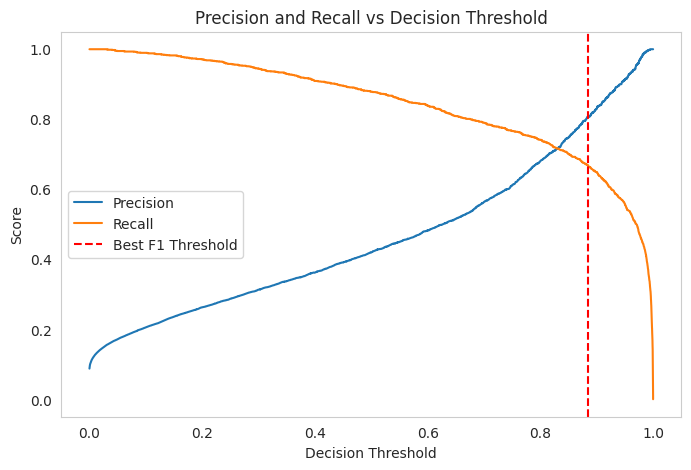

In [50]:
plt.figure(figsize=(8, 5))

plt.plot(
    thresholds,
    precision_values[:-1],
    label='Precision'
)

plt.plot(
    thresholds,
    recall_values[:-1],
    label='Recall'
)

plt.axvline(
    best_threshold,
    color='red',
    linestyle='--',
    label='Best F1 Threshold'
)

plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Decision Threshold')
plt.legend()
plt.grid()
plt.show()

In [51]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict probabilities for test data
y_test_prob = threshold_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
y_pred_tuned = (y_test_prob >= best_threshold).astype(int)

print("Tuned threshold predictions generated!")

Tuned threshold predictions generated!


In [52]:
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(y_test, y_pred_tuned)
tuned_recall = recall_score(y_test, y_pred_tuned)
tuned_f1 = f1_score(y_test, y_pred_tuned)

print("TUNED LOGISTIC REGRESSION PERFORMANCE")
print("--------------------------------------")
print("Threshold:", round(best_threshold, 4))
print("Accuracy :", round(tuned_accuracy * 100, 2), "%")
print("Precision:", round(tuned_precision * 100, 2), "%")
print("Recall   :", round(tuned_recall * 100, 2), "%")
print("F1 Score :", round(tuned_f1 * 100, 2), "%")

TUNED LOGISTIC REGRESSION PERFORMANCE
--------------------------------------
Threshold: 0.8837
Accuracy : 95.64 %
Precision: 80.86 %
Recall   : 66.27 %
F1 Score : 72.85 %


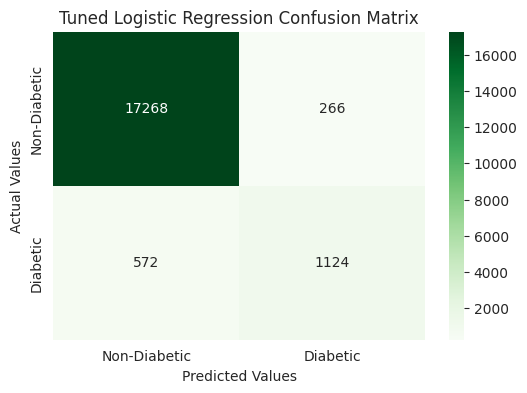

[[17268   266]
 [  572  1124]]


In [53]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)

plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Tuned Logistic Regression Confusion Matrix')
plt.show()

print(cm_tuned)

In [54]:
import pandas as pd
import matplotlib.pyplot as plt

final_comparison = pd.DataFrame({
    'Model': ['Original', 'Balanced', 'Tuned'],
    'Accuracy': [accuracy, balanced_accuracy, tuned_accuracy],
    'Precision': [precision, balanced_precision, tuned_precision],
    'Recall': [recall, balanced_recall, tuned_recall],
    'F1 Score': [f1, balanced_f1, tuned_f1]
})

print(final_comparison.round(4))


      Model  Accuracy  Precision  Recall  F1 Score
0  Original    0.9597     0.8699  0.6386    0.7365
1  Balanced    0.8844     0.4250  0.8797    0.5731
2     Tuned    0.9564     0.8086  0.6627    0.7285


In [55]:
from sklearn.metrics import roc_auc_score, roc_curve

final_model = baseline_model

y_prob = final_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.9599


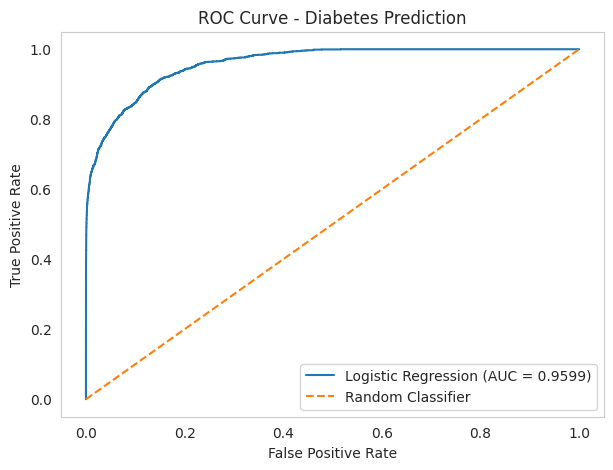

In [56]:
fpr, tpr, thresholds_roc = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Diabetes Prediction')
plt.legend()
plt.grid()
plt.show()

In [57]:
feature_names = final_model.named_steps['preprocessor'].get_feature_names_out()
coefficients = final_model.named_steps['classifier'].coef_[0]

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Odds_Ratio': np.exp(coefficients)
})

feature_importance['Absolute_Importance'] = abs(
    feature_importance['Coefficient']
)

feature_importance = feature_importance.sort_values(
    by='Absolute_Importance',
    ascending=False
)

print(feature_importance.drop(
    columns='Absolute_Importance'
).to_string(index=False))

                         Feature  Coefficient  Odds_Ratio
                num__HbA1c_level     2.478823   11.927223
              cat__gender_Female    -1.695464    0.183514
                cat__gender_Male    -1.399558    0.246706
        num__blood_glucose_level     1.361020    3.900170
                        num__age     1.065162    2.901310
    cat__smoking_history_No Info    -0.959653    0.383026
            binary__hypertension     0.746726    2.110080
           binary__heart_disease     0.740678    2.097357
                        num__bmi     0.580394    1.786742
cat__smoking_history_not current    -0.508555    0.601364
     cat__smoking_history_former    -0.462255    0.629862
      cat__smoking_history_never    -0.442746    0.642270
       cat__smoking_history_ever    -0.404129    0.667558
    cat__smoking_history_current    -0.331160    0.718090
               cat__gender_Other    -0.013477    0.986614


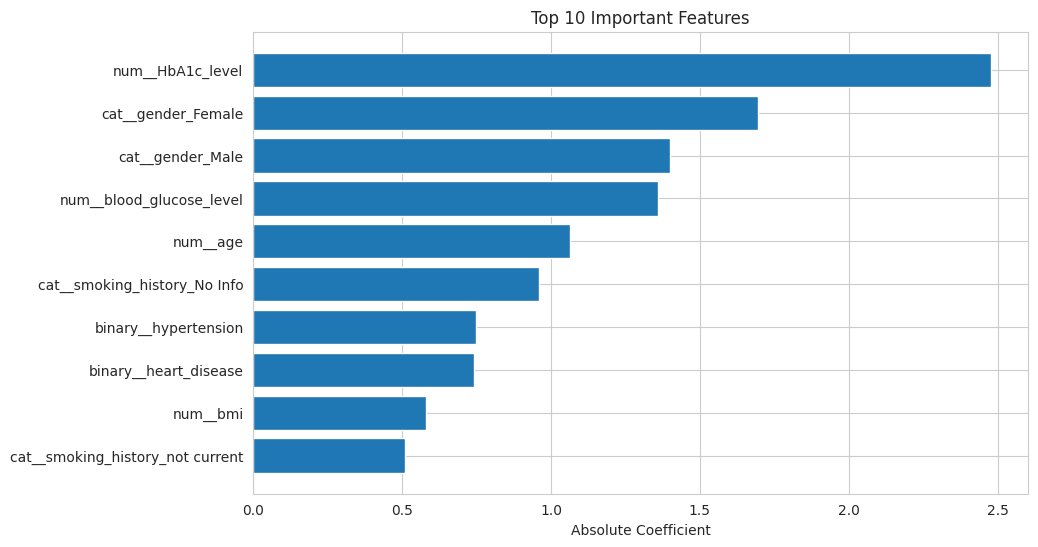

In [58]:
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(10).sort_values(
    'Absolute_Importance'
)

plt.barh(
    top_features['Feature'],
    top_features['Absolute_Importance']
)

plt.xlabel('Absolute Coefficient')
plt.title('Top 10 Important Features')
plt.show()

In [59]:
import joblib

joblib.dump(final_model, 'diabetes_logistic_regression.pkl')

print("Final model saved successfully!")

Final model saved successfully!


In [60]:
from google.colab import files

files.download('diabetes_logistic_regression.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 21.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 52.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [62]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Diabetes Prediction",
    page_icon="🩺",
    layout="centered"
)

model = joblib.load("diabetes_logistic_regression.pkl")

st.title("🩺 Diabetes Prediction System")
st.write("Logistic Regression based educational prediction application")

st.warning(
    "Educational project only. This tool is not a medical "
    "diagnostic system. Do not use its output for medical decisions."
)

st.subheader("Enter the input details")

gender = st.selectbox("Gender", ["Female", "Male", "Other"])

age = st.number_input(
    "Age",
    min_value=0.08,
    max_value=80.0,
    value=30.0
)

hypertension = st.selectbox(
    "Hypertension",
    [0, 1],
    format_func=lambda x: "Yes" if x == 1 else "No"
)

heart_disease = st.selectbox(
    "Heart Disease",
    [0, 1],
    format_func=lambda x: "Yes" if x == 1 else "No"
)

smoking_history = st.selectbox(
    "Smoking History",
    ["No Info", "never", "former", "current", "not current", "ever"]
)

bmi = st.number_input(
    "BMI",
    min_value=10.01,
    max_value=95.69,
    value=25.0
)

hba1c = st.number_input(
    "HbA1c Level",
    min_value=3.5,
    max_value=9.0,
    value=5.5
)

glucose = st.number_input(
    "Blood Glucose Level",
    min_value=80,
    max_value=300,
    value=100
)

if st.button("Predict"):

    input_data = pd.DataFrame([{
        "gender": gender,
        "age": age,
        "hypertension": hypertension,
        "heart_disease": heart_disease,
        "smoking_history": smoking_history,
        "bmi": bmi,
        "HbA1c_level": hba1c,
        "blood_glucose_level": glucose
    }])

    probability = model.predict_proba(input_data)[0][1]
    prediction = model.predict(input_data)[0]

    st.subheader("Prediction Result")

    st.write(f"Estimated model probability: {probability * 100:.2f}%")

    if prediction == 1:
        st.error("Model prediction: Diabetic class")
    else:
        st.success("Model prediction: Non-Diabetic class")

    st.caption(
        "This is a machine-learning estimate, not a diagnosis. "
        "Consult a qualified healthcare professional for medical advice."
    )

Writing app.py


In [63]:
%%writefile requirements.txt

streamlit
pandas
numpy
scikit-learn
joblib

Writing requirements.txt


In [64]:
import sklearn
import pandas
import numpy
import joblib

with open("requirements.txt", "w") as f:
    f.write("streamlit\n")
    f.write(f"pandas=={pandas.__version__}\n")
    f.write(f"numpy=={numpy.__version__}\n")
    f.write(f"scikit-learn=={sklearn.__version__}\n")
    f.write(f"joblib=={joblib.__version__}\n")

from google.colab import files

files.download("app.py")
files.download("requirements.txt")
files.download("diabetes_logistic_regression.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>